In [23]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [24]:
df = pd.read_csv('telco_customer_data_v2.csv')

In [25]:
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
54601,CUST54602,Female,0,No,No,12.0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Month-to-month,Yes,Bank transfer (automatic),29.59,355.08,No
25357,CUST25358,Male,0,Yes,No,11.0,Yes,Yes,DSL,No,...,No,No,Yes,No,Two year,Yes,Electronic check,112.57,1238.27,No
42425,CUST42426,Male,0,No,Yes,21.0,Yes,Yes,Fiber optic,No,...,No,No internet service,No,No,Month-to-month,No,Credit card (automatic),99.02,2079.42,Yes
39534,CUST39535,male,0,Yes,No,35.0,No,No phone service,Fiber optic,No,...,No,No,Yes,No,Month-to-month,Yes,Electronic check,44.21,1547.35,No
756,CUST00757,Female,0,No,No,31.0,Yes,No,DSL,Yes,...,No,NaN,Yes,No,One year,No,Electronic check,51.25,1588.75$,No


In [26]:
df.shape

(70000, 21)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        70000 non-null  object 
 1   gender            69252 non-null  object 
 2   SeniorCitizen     69341 non-null  object 
 3   Partner           66470 non-null  object 
 4   Dependents        66435 non-null  object 
 5   tenure            69433 non-null  float64
 6   PhoneService      70000 non-null  object 
 7   MultipleLines     68132 non-null  object 
 8   InternetService   70000 non-null  object 
 9   OnlineSecurity    67078 non-null  object 
 10  OnlineBackup      67253 non-null  object 
 11  DeviceProtection  67106 non-null  object 
 12  TechSupport       67267 non-null  object 
 13  StreamingTV       67173 non-null  object 
 14  StreamingMovies   67215 non-null  object 
 15  Contract          70000 non-null  object 
 16  PaperlessBilling  70000 non-null  object

In [28]:
df.isnull().sum()

customerID             0
gender               748
SeniorCitizen        659
Partner             3530
Dependents          3565
tenure               567
PhoneService           0
MultipleLines       1868
InternetService        0
OnlineSecurity      2922
OnlineBackup        2747
DeviceProtection    2894
TechSupport         2733
StreamingTV         2827
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod       3569
MonthlyCharges       388
TotalCharges        1062
Churn                  0
dtype: int64

In [29]:
df["customerID"] = df["customerID"].str.strip()

In [30]:
print(df["customerID"].str.contains(r"^\s|\s$", na=False).sum())

0


In [31]:
df["customerID"].duplicated().sum()

np.int64(0)

In [34]:
df['Churn'].value_counts()

Churn
No          37057
Yes         32713
Unknown        54
N              46
CHURNED        46
NO CHURN       45
Y              39
Name: count, dtype: int64

In [37]:
for i, value in df["Churn"].items():

    if pd.isna(value):
        continue

    value = str(value).strip().upper()

    if value in ["Y", "YES", "CHURNED"]:
        df.at[i, "Churn"] = "Yes"

    elif value in ["N", "NO", "NO CHURN"]:
        df.at[i, "Churn"] = "No"

In [38]:
df['Churn'].value_counts()

Churn
No         37148
Yes        32798
Unknown       54
Name: count, dtype: int64

In [39]:
known = df['Churn'][df['Churn'] != 'Unknown']
proportions = known.value_counts(normalize=True)
print(proportions)

Churn
No     0.531095
Yes    0.468905
Name: proportion, dtype: float64


In [40]:
unknown_mask = df['Churn'] == 'Unknown'


In [41]:
np.random.seed(42)   
df.loc[unknown_mask, 'Churn'] = np.random.choice(
    proportions.index,          
    size=unknown_mask.sum(),    
    p=proportions.values       
)

In [42]:
df['Churn'].value_counts()

Churn
No     37179
Yes    32821
Name: count, dtype: int64

In [43]:
df['gender'].value_counts()

gender
Female    34110
Male      33252
Man         500
male        374
FEMALE      351
m           339
f           326
Name: count, dtype: int64

In [48]:
df['gender'] = df['gender'].str.strip().str.lower()
gender_map = {
    'male': 'Male',
    'man': 'Male',
    'm': 'Male',
    'female': 'Female',
    'f': 'Female',
}
df['gender'] = df['gender'].map(gender_map)
print(df['gender'].value_counts(dropna=False))

gender
Female    34787
Male      34465
NaN         748
Name: count, dtype: int64


In [47]:
df['gender'].value_counts()

gender
Female    34461
Male      33252
Man         500
male        374
m           339
f           326
Name: count, dtype: int64

In [56]:
proportions = df['gender'].value_counts(normalize=True)
print(proportions)
missing_mask = df['gender'].isnull()
np.random.seed(42)
df.loc[missing_mask, 'gender'] = np.random.choice(
    proportions.index,          
    size=missing_mask.sum(),    
    p=proportions.values
)
print(df['gender'].value_counts(dropna=False))


gender
Female    0.502325
Male      0.497675
Name: proportion, dtype: float64
gender
Female    35160
Male      34840
Name: count, dtype: int64


In [61]:
print(df['SeniorCitizen'].value_counts(dropna=False))

SeniorCitizen
0             52405
1             10388
Yes            3559
No             2739
NaN             659
not senior      250
Name: count, dtype: int64


In [62]:
senior_map = {
    '1': 'Yes',
    'yes': 'Yes',
    '0': 'No',
    'no': 'No',
    'not senior': 'No',
}
df['SeniorCitizen'] = df['SeniorCitizen'].map(senior_map)

In [63]:
proportions = df['SeniorCitizen'].value_counts(normalize=True)
missing_mask = df['SeniorCitizen'].isnull()

np.random.seed(42)
df.loc[missing_mask, 'SeniorCitizen'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)

In [64]:
print(df['SeniorCitizen'].value_counts(dropna=False))

SeniorCitizen
No     58484
Yes    11516
Name: count, dtype: int64


In [65]:
np.random.seed(42)   

for col in ['Partner', 'Dependents']:
    print(f"\n--- {col} before ---")
    print(df[col].value_counts(dropna=False))

    df[col] = df[col].str.strip().str.lower()
    df[col] = df[col].map({'yes': 'Yes', 'no': 'No'})

    proportions = df[col].value_counts(normalize=True)
    missing_mask = df[col].isnull()

    df.loc[missing_mask, col] = np.random.choice(
        proportions.index,
        size=missing_mask.sum(),
        p=proportions.values
    )

    print(f"--- {col} after ---")
    print(df[col].value_counts(dropna=False))


--- Partner before ---
Partner
No     38344
Yes    28126
NaN     3530
Name: count, dtype: int64
--- Partner after ---
Partner
No     40340
Yes    29660
Name: count, dtype: int64

--- Dependents before ---
Dependents
No     45375
Yes    21060
NaN     3565
Name: count, dtype: int64
--- Dependents after ---
Dependents
No     47865
Yes    22135
Name: count, dtype: int64


In [67]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure               567
PhoneService           0
MultipleLines       1868
InternetService        0
OnlineSecurity      2922
OnlineBackup        2747
DeviceProtection    2894
TechSupport         2733
StreamingTV         2827
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod       3569
MonthlyCharges       388
TotalCharges        1062
Churn                  0
dtype: int64

In [71]:
df['MultipleLines'].value_counts()

MultipleLines
Yes                 34681
No                  25192
No phone service     8259
Name: count, dtype: int64

In [73]:
known = df['MultipleLines'][df['MultipleLines'] != 'No phone service']
proportions = known.value_counts(normalize=True)
print(proportions)
missing_mask = df['MultipleLines'].isnull()
print("Missing values:", missing_mask.sum())

df.loc[missing_mask, 'MultipleLines'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)
print(df['MultipleLines'].value_counts(dropna=False))

MultipleLines
Yes    0.580073
No     0.419927
Name: proportion, dtype: float64
Missing values: 0
MultipleLines
Yes                 36551
No                  26460
No phone service     6989
Name: count, dtype: int64


In [79]:
df['TechSupport'].value_counts()

TechSupport
No                     39401
No internet service    16616
Yes                    11239
Y                          7
True                       4
Name: count, dtype: int64

In [80]:
np.random.seed(42)

print(df['TechSupport'].value_counts(dropna=False))

df['TechSupport'] = df['TechSupport'].str.strip().str.lower()
df['TechSupport'] = df['TechSupport'].map({
    'yes': 'Yes',
    'y': 'Yes',
    'true': 'Yes',
    'no': 'No',
    'no internet service': 'No internet service',
})

known = df['TechSupport'][df['TechSupport'] != 'No internet service']
proportions = known.value_counts(normalize=True)
print(proportions)

missing_mask = df['TechSupport'].isnull()
df.loc[missing_mask, 'TechSupport'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)

print(df['TechSupport'].value_counts(dropna=False))

TechSupport
No                     39401
No internet service    16616
Yes                    11239
NaN                     2733
Y                          7
True                       4
Name: count, dtype: int64
TechSupport
No     0.777892
Yes    0.222108
Name: proportion, dtype: float64
TechSupport
No                     41529
No internet service    16616
Yes                    11855
Name: count, dtype: int64


In [81]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure               567
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity      2922
OnlineBackup        2747
DeviceProtection    2894
TechSupport            0
StreamingTV         2827
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod       3569
MonthlyCharges       388
TotalCharges        1062
Churn                  0
dtype: int64

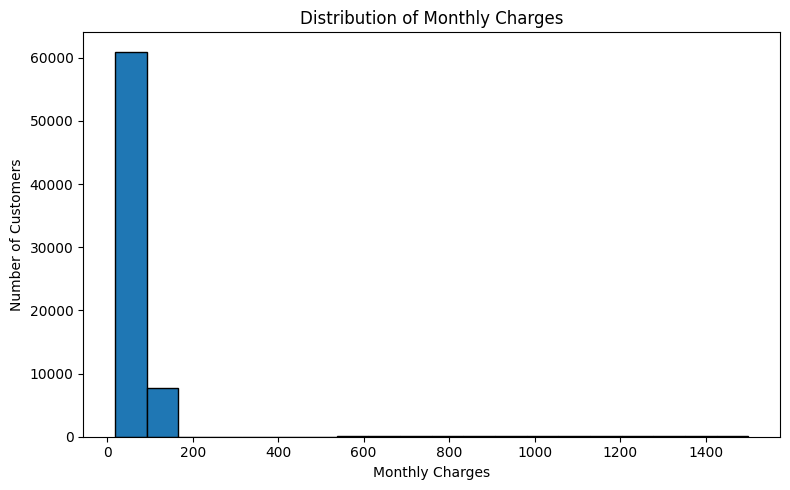

In [84]:
df["MonthlyCharges"].dropna().plot(
    kind="hist", bins=20, figsize=(8, 5), edgecolor="black"
)

plt.title("Distribution of Monthly Charges")
plt.xlabel("Monthly Charges")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [85]:
print("Missing before:", df['MonthlyCharges'].isnull().sum())

mode_value = df['MonthlyCharges'].mode()[0]
print("Mode:", mode_value)

df['MonthlyCharges'] = df['MonthlyCharges'].fillna(mode_value)

print("Missing after:", df['MonthlyCharges'].isnull().sum())

Missing before: 388
Mode: 28.49
Missing after: 0


In [92]:
df['TotalCharges'].value_counts()

TotalCharges
0.00       5736
484.80        8
364.14        8
554.40        8
409.50        8
           ... 
1226.21       1
1204.41       1
3794.70       1
442.72        1
217.23        1
Name: count, Length: 48189, dtype: int64

In [88]:
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"], errors="coerce"
)
mode_value = df['TotalCharges'].mode()[0]
print("Mode:", mode_value)
df['TotalCharges'] = df['TotalCharges'].fillna(mode_value)
df['TotalCharges'].isnull().sum()

Mode: 0.0


np.int64(0)

In [93]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure               567
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity      2922
OnlineBackup        2747
DeviceProtection    2894
TechSupport            0
StreamingTV         2827
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod       3569
MonthlyCharges         0
TotalCharges           0
Churn                  0
dtype: int64

In [94]:
df['PaymentMethod'].value_counts()

PaymentMethod
Electronic check             27841
Bank transfer (automatic)    14102
Mailed check                 13963
Credit card (automatic)      10400
BANK TRANSFER                  125
Name: count, dtype: int64

In [95]:
df['PaymentMethod'] = df['PaymentMethod'].str.strip()
df['PaymentMethod'] = df['PaymentMethod'].replace('BANK TRANSFER', 'Bank transfer (automatic)')

In [96]:
proportions = df['PaymentMethod'].value_counts(normalize=True)
print(proportions)
missing_mask = df['PaymentMethod'].isnull()
df.loc[missing_mask, 'PaymentMethod'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)
print(df['PaymentMethod'].value_counts(dropna=False))

PaymentMethod
Electronic check             0.419097
Bank transfer (automatic)    0.214162
Mailed check                 0.210188
Credit card (automatic)      0.156553
Name: proportion, dtype: float64
PaymentMethod
Electronic check             29381
Bank transfer (automatic)    14971
Mailed check                 14709
Credit card (automatic)      10939
Name: count, dtype: int64


In [97]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure               567
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity      2922
OnlineBackup        2747
DeviceProtection    2894
TechSupport            0
StreamingTV         2827
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
Churn                  0
dtype: int64

In [99]:
df['tenure'].value_counts()

tenure
2.0     1771
5.0     1768
17.0    1748
24.0    1743
9.0     1738
        ... 
61.0     106
54.0     104
56.0     101
64.0     101
59.0      99
Name: count, Length: 75, dtype: int64

In [100]:
invalid = (df['tenure'] < 0) | (df['tenure'] > 72)
df.loc[invalid, 'tenure'] = np.nan
df['tenure'].value_counts()

tenure
2.0     1771
5.0     1768
17.0    1748
24.0    1743
9.0     1738
        ... 
67.0     106
54.0     104
56.0     101
64.0     101
59.0      99
Name: count, Length: 72, dtype: int64

In [101]:
mode_value = df['tenure'].mode()[0]
print("Mode:", mode_value)
df['tenure'] = df['tenure'].fillna(mode_value)

Mode: 2.0


In [102]:
df['tenure'] = df['tenure'].astype(int)

In [103]:
print("Missing after:", df['tenure'].isnull().sum())

Missing after: 0


In [105]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity      2922
OnlineBackup        2747
DeviceProtection    2894
TechSupport            0
StreamingTV         2827
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
Churn                  0
dtype: int64

In [106]:
df['StreamingTV'].value_counts()

StreamingTV
No                     39198
No internet service    16610
Yes                    11355
Y                          5
True                       5
Name: count, dtype: int64

In [107]:
df['StreamingTV'] = df['StreamingTV'].str.strip().str.lower()
df['StreamingTV'] = df['StreamingTV'].map({
    'yes': 'Yes',
    'y': 'Yes',
    'true': 'Yes',
    'no': 'No',
    'no internet service': 'No internet service',
})

In [108]:
known = df['StreamingTV'][df['StreamingTV'] != 'No internet service']
proportions = known.value_counts(normalize=True)
print(proportions)

StreamingTV
No     0.775231
Yes    0.224769
Name: proportion, dtype: float64


In [109]:
missing_mask = df['StreamingTV'].isnull()
df.loc[missing_mask, 'StreamingTV'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)

In [110]:
print(df['StreamingTV'].value_counts(dropna=False))

StreamingTV
No                     41437
No internet service    16610
Yes                    11953
Name: count, dtype: int64


In [111]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity      2922
OnlineBackup        2747
DeviceProtection    2894
TechSupport            0
StreamingTV            0
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
Churn                  0
dtype: int64

In [112]:
df['OnlineSecurity'].value_counts()

OnlineSecurity
No                     39195
No internet service    16672
Yes                    11202
True                       6
Y                          3
Name: count, dtype: int64

In [113]:
df['OnlineSecurity'] = df['OnlineSecurity'].str.strip().str.lower()
df['OnlineSecurity'] = df['OnlineSecurity'].map({
    'yes': 'Yes',
    'y': 'Yes',
    'true': 'Yes',
    'no': 'No',
    'no internet service': 'No internet service',
})

In [114]:
known = df['OnlineSecurity'][df['OnlineSecurity'] != 'No internet service']
proportions = known.value_counts(normalize=True)
print(proportions)


OnlineSecurity
No     0.777586
Yes    0.222414
Name: proportion, dtype: float64


In [115]:
missing_mask = df['OnlineSecurity'].isnull()
df.loc[missing_mask, 'OnlineSecurity'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)

In [116]:
df['OnlineSecurity'].value_counts()

OnlineSecurity
No                     41452
No internet service    16672
Yes                    11876
Name: count, dtype: int64

In [117]:
df['OnlineBackup'].value_counts()

OnlineBackup
No                     39308
No internet service    16691
Yes                    11237
Y                         10
True                       7
Name: count, dtype: int64

In [118]:
df['OnlineBackup'] = df['OnlineBackup'].str.strip().str.lower()
df['OnlineBackup'] = df['OnlineBackup'].map({
    'yes': 'Yes',
    'y': 'Yes',
    'true': 'Yes',
    'no': 'No',
    'no internet service': 'No internet service',
})

In [119]:
known = df['OnlineBackup'][df['OnlineBackup'] != 'No internet service']
proportions = known.value_counts(normalize=True)
print(proportions)

OnlineBackup
No     0.777422
Yes    0.222578
Name: proportion, dtype: float64


In [120]:
missing_mask = df['OnlineBackup'].isnull()
df.loc[missing_mask, 'OnlineBackup'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)

In [121]:
print(df['OnlineBackup'].value_counts(dropna=False))

OnlineBackup
No                     41426
No internet service    16691
Yes                    11883
Name: count, dtype: int64


In [122]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity         0
OnlineBackup           0
DeviceProtection    2894
TechSupport            0
StreamingTV            0
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
Churn                  0
dtype: int64

In [123]:
df['DeviceProtection'].value_counts()

DeviceProtection
No                     39199
No internet service    16623
Yes                    11277
Y                          6
True                       1
Name: count, dtype: int64

In [124]:
df['DeviceProtection'] = df['DeviceProtection'].str.strip().str.lower()
df['DeviceProtection'] = df['DeviceProtection'].map({
    'yes': 'Yes',
    'y': 'Yes',
    'true': 'Yes',
    'no': 'No',
    'no internet service': 'No internet service',
})

In [125]:
known = df['DeviceProtection'][df['DeviceProtection'] != 'No internet service']
proportions = known.value_counts(normalize=True)
print(proportions)

DeviceProtection
No     0.776479
Yes    0.223521
Name: proportion, dtype: float64


In [126]:
missing_mask = df['DeviceProtection'].isnull()
df.loc[missing_mask, 'DeviceProtection'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)

In [127]:
print(df['DeviceProtection'].value_counts(dropna=False))

DeviceProtection
No                     41451
No internet service    16623
Yes                    11926
Name: count, dtype: int64


In [128]:
df.isnull().sum()

customerID             0
gender                 0
SeniorCitizen          0
Partner                0
Dependents             0
tenure                 0
PhoneService           0
MultipleLines          0
InternetService        0
OnlineSecurity         0
OnlineBackup           0
DeviceProtection       0
TechSupport            0
StreamingTV            0
StreamingMovies     2785
Contract               0
PaperlessBilling       0
PaymentMethod          0
MonthlyCharges         0
TotalCharges           0
Churn                  0
dtype: int64

In [129]:
df['StreamingMovies'].value_counts()

StreamingMovies
No                     39189
No internet service    16744
Yes                    11271
Y                          7
True                       4
Name: count, dtype: int64

In [130]:
df['StreamingMovies'] = df['StreamingMovies'].str.strip().str.lower()
df['StreamingMovies'] = df['StreamingMovies'].map({
    'yes': 'Yes',
    'y': 'Yes',
    'true': 'Yes',
    'no': 'No',
    'no internet service': 'No internet service',
})

In [131]:
known = df['StreamingMovies'][df['StreamingMovies'] != 'No internet service']
proportions = known.value_counts(normalize=True)
print(proportions)

StreamingMovies
No     0.776466
Yes    0.223534
Name: proportion, dtype: float64


In [132]:
missing_mask = df['StreamingMovies'].isnull()
df.loc[missing_mask, 'StreamingMovies'] = np.random.choice(
    proportions.index,
    size=missing_mask.sum(),
    p=proportions.values
)


In [133]:
print(df['StreamingMovies'].value_counts(dropna=False))

StreamingMovies
No                     41345
No internet service    16744
Yes                    11911
Name: count, dtype: int64


In [134]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [135]:
df.to_csv('telco_customer_data_cleaned.csv', index=False)
import os
print("Saved to:", os.path.join(os.getcwd(), 'telco_customer_data_cleaned.csv'))

Saved to: /Users/aadilqayum/Data Analytics project/telco_customer_data_cleaned.csv


In [136]:
df.sample(5)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
24370,CUST24371,Male,No,No,Yes,30,Yes,No,DSL,No,...,No,No,Yes,Yes,Month-to-month,Yes,Credit card (automatic),41.73,1251.90,Yes
4094,CUST04095,Male,Yes,No,No,40,Yes,Yes,Fiber optic,No,...,No,Yes,Yes,No,Month-to-month,No,Credit card (automatic),47.70,0.00,No
63703,CUST63704,Male,No,No,No,10,Yes,Yes,Fiber optic,No,...,No,No,No,No,Two year,Yes,Electronic check,95.27,952.70,No
58297,CUST58298,Male,No,No,No,43,Yes,Yes,Fiber optic,No,...,Yes,No,No,No,Month-to-month,Yes,Electronic check,58.95,2534.85,No
38964,CUST38965,Female,No,No,No,23,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,Yes,Electronic check,70.98,1632.54,No
